# Karpowicz 2025 — exploring the source data

Two NWB files from BrainGate2 participant T11, recorded 153 and 427 days after implant, holding closed-loop cursor control at 50 Hz. This notebook opens the deposit as it ships, shows how its blocks and trials are organized, and works through the three places where the file says one thing and the numbers say another.

In [1]:
import h5py
import matplotlib.pyplot as plt
import numpy as np

from neuralshed.datasets.karpowicz_2025 import utils

## The deposit, and why `pynwb` will not open it

Two files, 262 MB together. The names carry no ordering: `session2.nwb` is the earlier session, so this package keys them by day since implant instead.

In [2]:
# The Study resolves its own class-named subfolder, which is where `_download` lands the files.
data_dir = utils.DEFAULT_DATA_DIR

for session, filename in utils.SESSION_FILES.items():
    path = data_dir / filename
    size_mb = path.stat().st_size / 1e6
    print(f"{session}  <- {filename}  {size_mb:6.1f} MB  (implant day {utils.POST_IMPLANT_DAY[session]})")

T11_day153  <- session2.nwb   142.9 MB  (implant day 153)
T11_day427  <- session1.nwb   104.3 MB  (implant day 427)


In [3]:
from pynwb import NWBHDF5IO

# Both files de-identify `session_start_time` to 1900-10-01 with a seconds-resolution UTC
# offset, which dateutil refuses, so pynwb raises before reaching any data.
try:
    NWBHDF5IO(str(data_dir / "session1.nwb"), "r").read()
except Exception as error:
    print(f"{type(error).__name__}: {error}")

ParserError: Unknown string format: 1900-10-01T00:00:00-05:50:36


In [4]:
# h5py reads the same tree without parsing any dates.
with h5py.File(data_dir / "session1.nwb", "r") as handle:
    print("session_start_time :", handle["session_start_time"][()].decode())
    print("identifier         :", handle["identifier"][()].decode())
    print("subject            :", handle["general/subject/subject_id"][()].decode())
    print("description        :", handle["general/experiment_description"][()].decode())

session_start_time : 1900-10-01T00:00:00-05:50:36
identifier         : T11_1900.10.01
subject            : T11
description        : center-out to one of four targets


## Layout

Six acquisition streams share one clock, and one interval table holds the trials.

In [5]:
with h5py.File(data_dir / "session1.nwb", "r") as handle:
    for name in utils.STREAMS:
        dataset = handle[f"acquisition/{name}/data"]
        unit = handle[f"acquisition/{name}"].attrs.get("unit", "")
        print(f"acquisition/{name:15s} {str(dataset.shape):15s} {dataset.dtype}  unit={unit!r}")

    trials = handle["intervals/trials"]
    print()
    print("intervals/trials columns:", [key for key in trials.keys() if key != "id"])
    print("intervals/trials rows   :", trials["id"].shape[0])

acquisition/binned_spikes   (63157, 192)    float64  unit=''
acquisition/cursor_pos      (63157, 2)      float64  unit=''
acquisition/cursor_vel      (63157, 2)      float64  unit=''
acquisition/target_pos      (63157, 2)      float64  unit=''
acquisition/block_num       (63157, 1)      float64  unit=''
acquisition/cond_id         (63157, 1)      float64  unit=''

intervals/trials columns: ['block_num', 'cond_id', 'is_calibration', 'result', 'start_time', 'stop_time', 'tgt_x', 'tgt_y']
intervals/trials rows   : 472


## Quirk 1: the clock is in nanoseconds

NWB timestamps are nominally seconds. These are absolute Unix nanoseconds, so a raw difference between two of them is 20 million, not 0.02.

In [6]:
with h5py.File(data_dir / "session1.nwb", "r") as handle:
    raw = handle["acquisition/binned_spikes/timestamps"][:4]

print("raw timestamps      :", raw)
print("raw spacing         :", np.diff(raw))
print("spacing in seconds  :", np.diff(raw) / 1e9)
print("implied bin rate    :", 1e9 / np.diff(raw)[0], "Hz")

raw timestamps      : [1.60622543e+18 1.60622543e+18 1.60622543e+18 1.60622543e+18]
raw spacing         : [20000000. 20000000. 20000000.]
spacing in seconds  : [0.02 0.02 0.02]
implied bin rate    : 50.0 Hz


## Blocks

Only the task blocks were released, so block numbers skip and consecutive blocks can sit an hour apart. Each block is one near-continuous 20 ms grid, which is why `study.py` treats a block, not a session, as one timeline.

In [7]:
blocks = utils.list_blocks(data_dir)

print(f"{'block':22s} {'task':22s} {'bins':>7s} {'minutes':>8s} {'trials':>7s} {'targets':>8s} {'dropped':>8s}")
for ref in blocks:
    trials = utils.trials(ref)
    print(
        f"{ref.label:22s} {ref.task:22s} {utils.n_bins(ref):7d} "
        f"{utils.duration(ref) / 60:8.2f} {len(trials):7d} "
        f"{len(utils.target_layout(ref)):8d} {utils.dropped_bins(ref):8d}"
    )

block                  task                      bins  minutes  trials  targets  dropped
T11_day153_block03     centeroutcalibration     12123     4.04      33        8        0
T11_day153_block05     simonsequence             6865     2.29      61        4        0
T11_day153_block06     simonsequence             7004     2.33      58        4        0
T11_day153_block07     simonsequence             7212     2.40      62        4        1
T11_day153_block08     simonsequence             7116     2.37      60        4        1
T11_day153_block09     simonsequence             7294     2.43      64        4        0
T11_day153_block10     simonsequence             7721     2.57      64        4        0
T11_day153_block11     simonsequence             7565     2.52      63        4        0
T11_day153_block12     simonsequence             7533     2.51      59        4        0
T11_day153_block13     simonsequence             7843     2.61      60        4        0
T11_day153_block14   

## Trials are movements, not sequences

The task is a Simon memory game: four targets illuminate in order and T11 imagines right-hand movements to drive the cursor through the sequence. A released trial is one of those four movements, cut from the cursor's outward zero-crossing to 600 ms later or to target acquisition. `result` belongs to the whole sequence, so the four movements of one sequence share it.

In [8]:
simon = blocks[1]
trials = utils.trials(simon)

print(simon.label, "\n")
print(trials.head(8)[["trial_id", "cond_id", "tgt_x", "tgt_y", "result", "start_bin", "stop_bin"]].to_string(index=False))

lengths = (trials["stop_bin"] - trials["start_bin"]) / utils.FS
print()
print(f"movement length: median {np.median(lengths):.2f} s, 5th-95th {np.percentile(lengths, 5):.2f}-{np.percentile(lengths, 95):.2f} s")
print(f"movements in successful sequences: {trials['result'].mean():.1%}")

T11_day153_block05 

 trial_id  cond_id  tgt_x  tgt_y  result  start_bin  stop_bin
       33        3  -0.38   0.00       1        377       432
       34        1   0.38   0.00       1        441       472
       35        4   0.00  -0.38       1        484       519
       36        2   0.00   0.38       1        523       556
       37        3  -0.38   0.00       1        798       841
       38        1   0.38   0.00       1        846       879
       39        4   0.00  -0.38       1        892       925
       40        2   0.00   0.38       1        938       970

movement length: median 0.72 s, 5th-95th 0.58-0.94 s
movements in successful sequences: 85.2%


## Quirk 2: `cond_id` is block-local

The calibration block spends 1 to 8 on eight radial targets at radius 0.5. A Simon block uses only 1 to 4, on four cardinal targets at radius 0.375. The same number therefore means different targets in different blocks, so comparisons should go through `tgt_x` and `tgt_y`.

In [9]:
calibration = blocks[0]

for ref in (calibration, simon):
    table = utils.trials(ref)
    pairs = table.groupby("cond_id")[["tgt_x", "tgt_y"]].first()
    print(f"{ref.label} ({ref.task})")
    print(pairs.to_string())
    print()

T11_day153_block03 (centeroutcalibration)
         tgt_x  tgt_y
cond_id              
1         0.50   0.00
2         0.35   0.35
3         0.00   0.50
4        -0.35   0.35
5        -0.50   0.00
6        -0.35  -0.35
7        -0.00  -0.50
8         0.35  -0.35

T11_day153_block05 (simonsequence)
         tgt_x  tgt_y
cond_id              
1         0.38   0.00
2         0.00   0.38
3        -0.38   0.00
4         0.00  -0.38



## Quirk 3: `cursor_vel` is a per-bin displacement

Its unit string says `position/s`, but within a trial the change in `cursor_pos` from one bin to the next equals the released velocity almost exactly. Fitting the two with no intercept, per trial, puts the slope at 1 bin rather than 1 second, so `utils.get_stream` scales the stream by the bin rate and the Study declares `a.u./s` truthfully.

In [10]:
# `get_stream` already applies the correction, so undo it here to see the source values.
position = utils.get_stream(simon, "cursor_pos")
velocity = utils.get_stream(simon, "cursor_vel") / utils.FS

slopes = []
for trial in utils.trials(simon).itertuples():
    start, stop = int(trial.start_bin), int(trial.stop_bin)
    step = np.diff(position[start:stop], axis=0)
    if len(step) < 10 or np.abs(step).max() > 0.2:  # skip the automatic recentring jump
        continue
    slopes.append((step * velocity[start:stop - 1]).sum() / (velocity[start:stop - 1] ** 2).sum())

print(f"displacement per bin / released velocity: median {np.median(slopes):.3f} over {len(slopes)} trials")
print(f"so the released value is a displacement per {np.median(slopes):.2f} bin, i.e. per {np.median(slopes) / utils.FS * 1000:.0f} ms")

displacement per bin / released velocity: median 1.024 over 61 trials
so the released value is a displacement per 1.02 bin, i.e. per 20 ms


## What a block looks like

Cursor paths for the first movements of a Simon block, coloured by cued target, with the matching population firing rate underneath. The paths start near the centre because a trial begins at the cursor's outward zero-crossing.

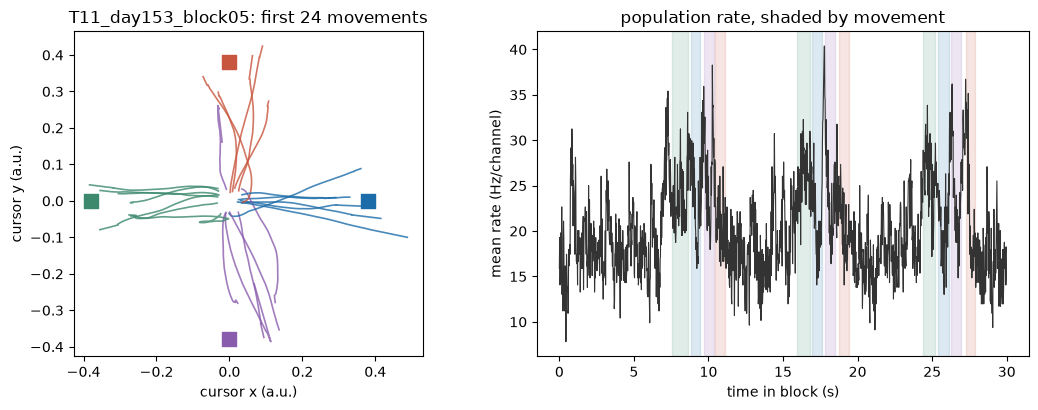

In [11]:
spikes = utils.get_stream(simon, "binned_spikes")
trials = utils.trials(simon)

figure, axes = plt.subplots(1, 2, figsize=(11, 4.2))
colors = {1: "#1b6ca8", 2: "#c8553d", 3: "#3c896d", 4: "#8a5cae"}

for trial in trials.head(24).itertuples():
    path = position[int(trial.start_bin):int(trial.stop_bin)]
    axes[0].plot(path[:, 0], path[:, 1], color=colors[trial.cond_id], alpha=0.8, linewidth=1.2)

for condition, (x, y) in trials.groupby("cond_id")[["tgt_x", "tgt_y"]].first().iterrows():
    axes[0].scatter([x], [y], color=colors[condition], s=90, marker="s", zorder=3)

axes[0].set(xlabel="cursor x (a.u.)", ylabel="cursor y (a.u.)", title=f"{simon.label}: first 24 movements")
axes[0].set_aspect("equal")

rate = spikes.sum(axis=1) * utils.FS / utils.N_CHANNELS
window = slice(0, 1500)
axes[1].plot(np.arange(window.stop) / utils.FS, rate[window], linewidth=0.8, color="#333333")
for trial in trials[trials["start_bin"] < window.stop].itertuples():
    axes[1].axvspan(trial.start_bin / utils.FS, trial.stop_bin / utils.FS, color=colors[trial.cond_id], alpha=0.15)
axes[1].set(xlabel="time in block (s)", ylabel="mean rate (Hz/channel)", title="population rate, shaded by movement")

figure.tight_layout()

## Summary

- 20 blocks over two sessions, 49.9 minutes and 1,116 movements, at 50 Hz on 192 channels.
- `pynwb` cannot open the files, the clock is in nanoseconds, and `cursor_vel` is a per-bin displacement. `utils.py` handles all three.
- `cond_id` only means something inside its own block; the target coordinates are the portable label.
- The release drops 251 individual bins, 243 of them in day 427's calibration block, so trial times are resolved against the source timestamps rather than by assuming a perfect grid.